# Red Neuronal para Reconocer Dígitos (MNIST)

**Programa Especializado en IA · C-DAC Noida · ITEC · India 2026**

*Resuelto paso a paso — PhD (c) Luis Correa*

---
Construiremos una **red neuronal** con Keras/TensorFlow que reconoce dígitos escritos a mano del dataset **MNIST** (70,000 imágenes de 28×28 píxeles). Compararemos una red simple con una red con **capa oculta**.

## 1. Cargamos MNIST

Keras trae el dataset integrado, así que no hay que subir nada. Son 60,000 imágenes para entrenar y 10,000 para probar.

In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
print("Entrenamiento:", X_train.shape, " | Prueba:", X_test.shape)

Entrenamiento: (60000, 28, 28)  | Prueba: (10000, 28, 28)


Veamos una imagen con `plt.matshow`. Es un dígito de 28×28 píxeles.

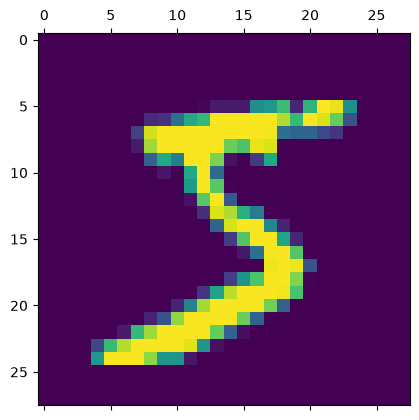

Etiqueta real: 5


In [2]:
plt.matshow(X_train[0])
plt.show()
print("Etiqueta real:", y_train[0])

## 2. Preparamos los datos

Los valores de los píxeles van de 0 a 255. Los **normalizamos** dividiendo entre 255 para que queden entre 0 y 1: así la red entrena mejor.

In [3]:
X_train = X_train / 255
X_test = X_test / 255

## 3. Red neuronal SIN capa oculta

Empezamos con lo más simple: aplanamos la imagen (28×28 = 784 números) y conectamos directo a 10 neuronas de salida (una por dígito), con activación **sigmoide**.

In [4]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(10, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train, y_train, epochs=5)

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 7:34 243ms/step - accuracy: 0.1562 - loss: 2.2796

 166/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 303us/step - accuracy: 0.7123 - loss: 1.1667  

 339/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 296us/step - accuracy: 0.7840 - loss: 0.8836

 513/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 293us/step - accuracy: 0.8148 - loss: 0.7502

... (60 outputs left out)

1344/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 336us/step - accuracy: 0.9241 - loss: 0.2685

1522/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 330us/step - accuracy: 0.9244 - loss: 0.2689

1700/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 325us/step - accuracy: 0.9250 - loss: 0.2667

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 323us/step - accuracy: 0.9251 - loss: 0.2663


Evaluamos la precisión sobre las 10,000 imágenes de prueba (debe rondar el **92-93%**).

In [5]:
model.evaluate(X_test, y_test)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - accuracy: 0.9688 - loss: 0.2696

193/313 ━━━━━━━━━━━━━━━━━━━━ 0s 261us/step - accuracy: 0.9122 - loss: 0.3142

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 279us/step - accuracy: 0.9261 - loss: 0.2665


[0.2665213942527771, 0.9261000156402588]

Vemos una predicción: la red devuelve 10 valores (confianza por dígito); el mayor es la respuesta.

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step

275/313 ━━━━━━━━━━━━━━━━━━━━ 0s 183us/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 218us/step


Predicción para la primera imagen de prueba: 7


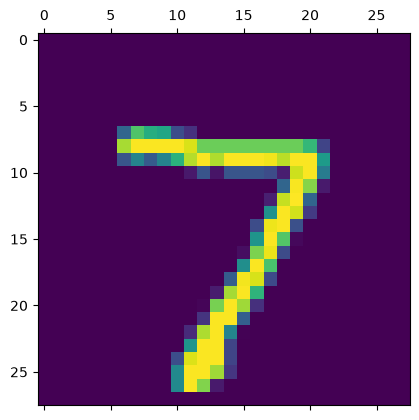

In [6]:
y_pred = model.predict(X_test)
print("Predicción para la primera imagen de prueba:", np.argmax(y_pred[0]))
plt.matshow(X_test[0])
plt.show()

Matriz de confusión de la red simple.

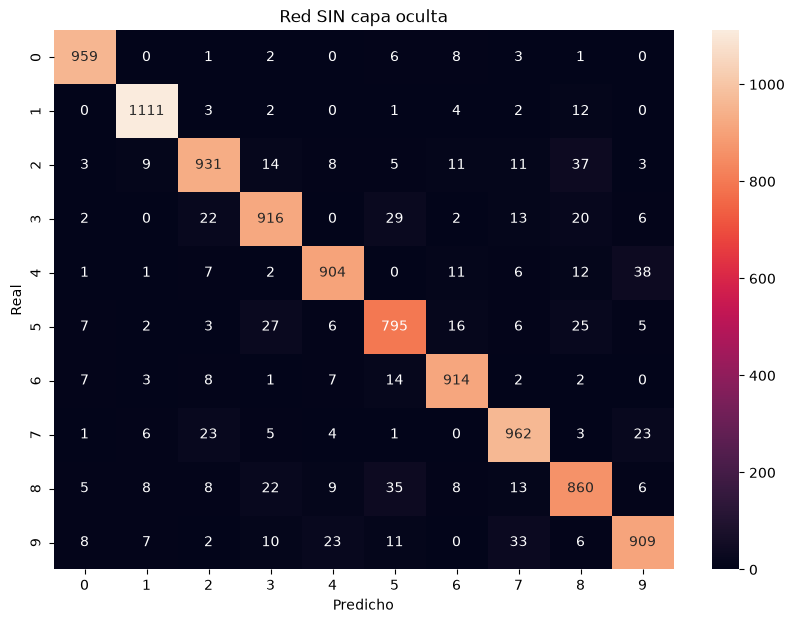

In [7]:
import seaborn as sn
y_pred_labels = [np.argmax(i) for i in y_pred]
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_pred_labels)
plt.figure(figsize=(10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicho'); plt.ylabel('Real')
plt.title('Red SIN capa oculta')
plt.show()

## 4. Red neuronal CON capa oculta

Agregamos una **capa oculta** de 100 neuronas con activación **ReLU**. Esto le da a la red más capacidad para aprender patrones y sube la precisión a ~**97-98%**.

In [8]:
model2 = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

model2.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

model2.fit(X_train, y_train, epochs=5)

Epoch 1/5


/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 8:00 256ms/step - accuracy: 0.1250 - loss: 2.4071

  75/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 683us/step - accuracy: 0.7025 - loss: 1.0925  

 154/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 661us/step - accuracy: 0.7934 - loss: 0.7654

 237/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 641us/step - accuracy: 0.8306 - loss: 0.6263

... (104 outputs left out)

1649/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 519us/step - accuracy: 0.9850 - loss: 0.0490

1748/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 518us/step - accuracy: 0.9849 - loss: 0.0493

1846/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 518us/step - accuracy: 0.9848 - loss: 0.0496

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 520us/step - accuracy: 0.9848 - loss: 0.0494


Evaluamos la red con capa oculta: la precisión sube notablemente.

In [9]:
model2.evaluate(X_test, y_test)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 1.0000 - loss: 0.0086

160/313 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step - accuracy: 0.9668 - loss: 0.1047

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 320us/step - accuracy: 0.9740 - loss: 0.0839


[0.0838678628206253, 0.9739999771118164]

Matriz de confusión de la red con capa oculta (la diagonal es más fuerte: más aciertos).

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step

217/313 ━━━━━━━━━━━━━━━━━━━━ 0s 232us/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 271us/step


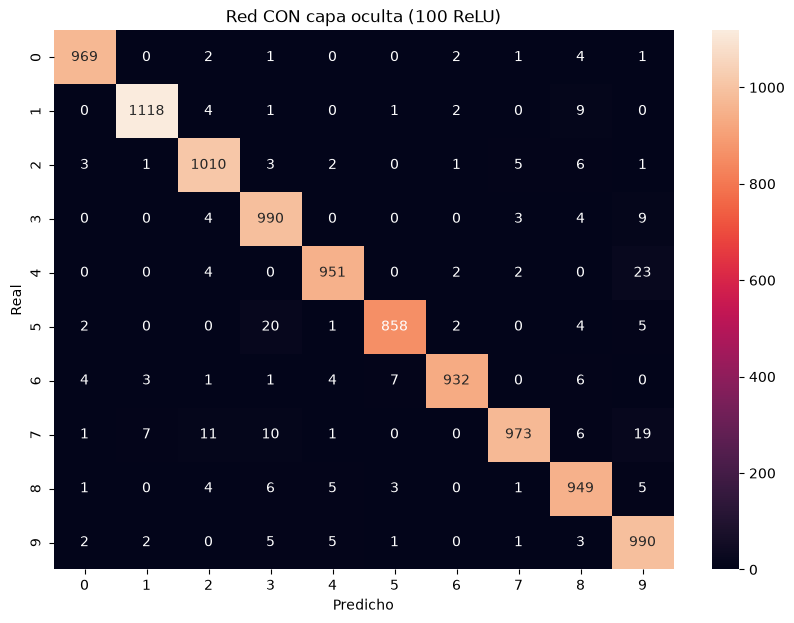

In [10]:
y_pred2 = model2.predict(X_test)
y_pred2_labels = [np.argmax(i) for i in y_pred2]
cm2 = tf.math.confusion_matrix(labels=y_test, predictions=y_pred2_labels)
plt.figure(figsize=(10,7))
sn.heatmap(cm2, annot=True, fmt='d')
plt.xlabel('Predicho'); plt.ylabel('Real')
plt.title('Red CON capa oculta (100 ReLU)')
plt.show()

## Ejercicio práctico

**Enunciado:** Experimentar con una red **más grande** (más neuronas y más capas) y comparar la precisión con las redes anteriores.

**Paso 1.** Construimos una red con dos capas ocultas (256 y 128 neuronas ReLU).

In [11]:
model3 = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

model3.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

model3.fit(X_train, y_train, epochs=5)

Epoch 1/5


/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 13:03 418ms/step - accuracy: 0.0625 - loss: 2.3492

  52/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 981us/step - accuracy: 0.7254 - loss: 0.9802   

 106/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 956us/step - accuracy: 0.8098 - loss: 0.6701

 155/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 982us/step - accuracy: 0.8389 - loss: 0.5696

... (191 outputs left out)

1754/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 951us/step - accuracy: 0.9893 - loss: 0.0330

1806/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 952us/step - accuracy: 0.9893 - loss: 0.0330

1860/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 951us/step - accuracy: 0.9894 - loss: 0.0328

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 954us/step - accuracy: 0.9895 - loss: 0.0327


**Paso 2.** Evaluamos y comparamos las tres redes.

In [12]:
acc1 = model.evaluate(X_test, y_test, verbose=0)[1]
acc2 = model2.evaluate(X_test, y_test, verbose=0)[1]
acc3 = model3.evaluate(X_test, y_test, verbose=0)[1]
print(f"Red sin capa oculta        : {acc1:.4f}")
print(f"Red con 1 capa (100)       : {acc2:.4f}")
print(f"Red con 2 capas (256,128)  : {acc3:.4f}")

Red sin capa oculta        : 0.9261
Red con 1 capa (100)       : 0.9740
Red con 2 capas (256,128)  : 0.9803


**Paso 3.** Gráfica comparativa de las precisiones.

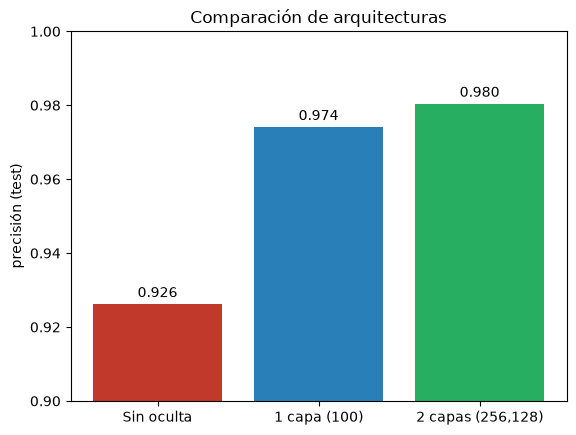

In [13]:
modelos = ['Sin oculta', '1 capa (100)', '2 capas (256,128)']
accs = [acc1, acc2, acc3]
plt.bar(modelos, accs, color=['#c0392b', '#2980b9', '#27ae60'])
plt.ylim(0.9, 1.0)
plt.ylabel('precisión (test)')
plt.title('Comparación de arquitecturas')
for i, v in enumerate(accs):
    plt.text(i, v + 0.002, f"{v:.3f}", ha='center')
plt.show()

**Conclusión:** agregar **capas ocultas** y más neuronas mejora la precisión frente a la red simple, porque la red puede aprender patrones más complejos de los dígitos. La mejora más grande es pasar de 0 a 1 capa oculta; después las ganancias son menores. Con 5 épocas ya se supera el 97-98% en MNIST.